# EDA Jobmarket

Ein einfacher Blick auf den ausgestochenen Markt aus `eda_keksausstecher.ipynb`
(`data/processed/market_v1.parquet`): Wer ist drin, wie lang sind die Texte, wie viele ESCO-Labels
haben sie, und wie verteilen sich Englischniveau und Erfahrung?

Zur Erinnerung, der Markt besteht aus:
- **Jobs:** 20 Data-Science-Stellen
- **Liste:** 60 CVs, die feste „Konkurrenz“ – 20 Kern (Data Science), 20 Rand (Python), 20 Außen (PHP)
- **Zwillinge:** 120 Ausgangs-CVs für die Zwillinge – 70 Kern, 30 Rand, 20 Außen (Kontrolle)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MARKET_PATH = Path("../data/processed/market_v1.parquet")
CV_PATH = Path("../data/raw/djinni/cv_profiles_en.parquet")
JOB_PATH = Path("../data/raw/djinni/job_postings_en.parquet")

# Farb-/Stilkonstanten (konsistent mit den anderen EDA-Notebooks)
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"
ORANGE = "#eb6834"
BLUE_ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]

# Ringe sind geordnet: Kern dunkel, Außen hell. Jobs in Orange.
FARBEN = {"Kern": "#104281", "Rand": "#2a78d6", "Außen": "#86b6ef", "Job": ORANGE}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 10,
})

## 1. Daten laden

Die Parquet-Datei enthält nur IDs und ein paar Kennzahlen. Für Englischniveau, Erfahrung und
Titel holen wir die Rohdaten über die `id` dazu.

In [2]:
market = pd.read_parquet(MARKET_PATH)
market.head()

,id,doc_type,role,ring,test,Primary Keyword,assigned_job_id,n_words,n_labels,seed
0,909c9714-ca46-5b39-96d6-88fb41384cb4,cv,list_A,A,NaN,Data Science,NaN,192,19,42
1,af68454b-9162-58d5-854b-913bf17282d2,cv,list_A,A,NaN,Data Science,NaN,223,16,42
2,98bd793d-741d-5c3d-8b89-6d5d08d4b581,cv,list_A,A,NaN,Data Science,NaN,339,12,42
3,5d8f04d4-8de2-5273-b12f-2ed22f9bf86f,cv,list_A,A,NaN,Data Science,NaN,257,19,42
4,e4a14c40-cddd-5298-af31-4f9075b2f1e2,cv,list_A,A,NaN,Data Science,NaN,117,22,42


In [3]:
# Lesbare Namen: "A" -> "Kern" usw. und eine Spalte "gruppe" für die Plots
RING_NAME = {"A": "Kern", "B": "Rand", "C": "Außen"}
market["ring_name"] = market["ring"].map(RING_NAME).fillna("Job")

market["gruppe"] = "Jobs"
market.loc[market["role"].str.startswith("list"), "gruppe"] = "Liste " + market["ring_name"]
market.loc[market["role"] == "twin_source", "gruppe"] = "Zwillinge " + market["ring_name"]

GRUPPEN = ["Jobs", "Liste Kern", "Liste Rand", "Liste Außen", "Zwillinge Kern", "Zwillinge Rand", "Zwillinge Außen"]
market["gruppe"].value_counts().reindex(GRUPPEN)

gruppe
Jobs               20
Liste Kern         20
Liste Rand         20
Liste Außen        20
Zwillinge Kern     70
Zwillinge Rand     30
Zwillinge Außen    20
Name: count, dtype: int64

In [4]:
cv_raw = pd.read_parquet(CV_PATH, columns=["id", "Position", "English Level", "Experience Years"])
job_raw = pd.read_parquet(JOB_PATH, columns=["id", "Position", "Company Name", "Exp Years", "English Level", "Published"])

cvs = market[market["doc_type"] == "cv"].merge(cv_raw, on="id")
jobs = market[market["doc_type"] == "job"].merge(job_raw, on="id")

print(f"CVs: {len(cvs)} | Jobs: {len(jobs)}")

CVs: 180 | Jobs: 20


## 2. Wie groß ist jede Gruppe?

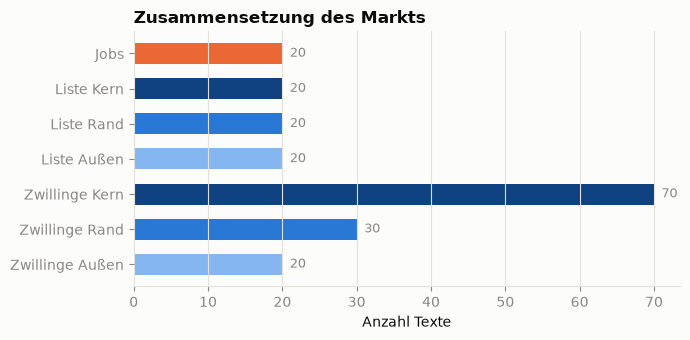

In [5]:
counts = market["gruppe"].value_counts().reindex(GRUPPEN)
farben = [FARBEN[market.loc[market["gruppe"] == g, "ring_name"].iloc[0]] for g in GRUPPEN]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(GRUPPEN[::-1], counts.values[::-1], color=farben[::-1], height=0.6)
for i, n in enumerate(counts.values[::-1]):
    ax.text(n + 1, i, str(n), va="center", fontsize=9, color=MUTED)
ax.set_xlabel("Anzahl Texte")
ax.set_title("Zusammensetzung des Markts", loc="left", color=INK, fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3. Wie lang sind die Texte?

Jobs sind meist deutlich länger als CVs. Interessant ist, ob sich die drei Ringe in der Länge
unterscheiden – Länge beeinflusst beide Scores (siehe `eda_keksausstecher.ipynb`, Abschnitt 7).

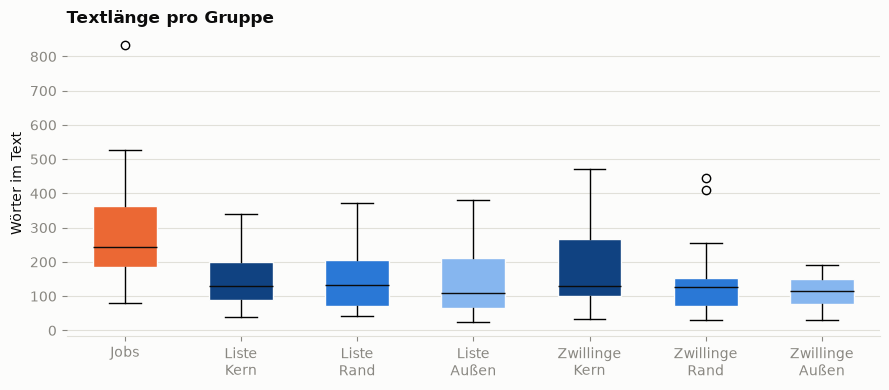

gruppe
Jobs               245.0
Liste Kern         128.5
Liste Rand         132.5
Liste Außen        110.5
Zwillinge Kern     129.5
Zwillinge Rand     127.0
Zwillinge Außen    114.5
Name: n_words, dtype: float64

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
daten = [market.loc[market["gruppe"] == g, "n_words"] for g in GRUPPEN]
box = ax.boxplot(daten, patch_artist=True, widths=0.55, medianprops={"color": INK})
for patch, farbe in zip(box["boxes"], farben):
    patch.set_facecolor(farbe)
    patch.set_edgecolor(SURFACE)
ax.set_xticks(range(1, len(GRUPPEN) + 1), [g.replace(" ", "\n") for g in GRUPPEN])
ax.set_ylabel("Wörter im Text")
ax.set_title("Textlänge pro Gruppe", loc="left", color=INK, fontweight="bold")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

market.groupby("gruppe")["n_words"].median().reindex(GRUPPEN)

## 4. Wie viele ESCO-Labels haben die Texte?

Alle Texte im Markt haben mindestens 5 Labels (Filter beim Ausstechen).

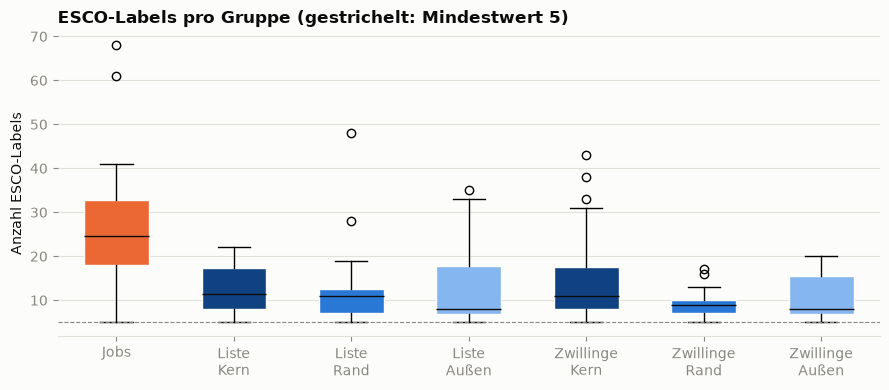

gruppe
Jobs               24.5
Liste Kern         11.5
Liste Rand         11.0
Liste Außen         8.0
Zwillinge Kern     11.0
Zwillinge Rand      9.0
Zwillinge Außen     8.0
Name: n_labels, dtype: float64

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
daten = [market.loc[market["gruppe"] == g, "n_labels"] for g in GRUPPEN]
box = ax.boxplot(daten, patch_artist=True, widths=0.55, medianprops={"color": INK})
for patch, farbe in zip(box["boxes"], farben):
    patch.set_facecolor(farbe)
    patch.set_edgecolor(SURFACE)
ax.axhline(5, color=MUTED, linewidth=0.8, linestyle="--")
ax.set_xticks(range(1, len(GRUPPEN) + 1), [g.replace(" ", "\n") for g in GRUPPEN])
ax.set_ylabel("Anzahl ESCO-Labels")
ax.set_title("ESCO-Labels pro Gruppe (gestrichelt: Mindestwert 5)", loc="left", color=INK, fontweight="bold")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

market.groupby("gruppe")["n_labels"].median().reindex(GRUPPEN)

Mehr Text, mehr Labels? Jeder Punkt ist ein CV.

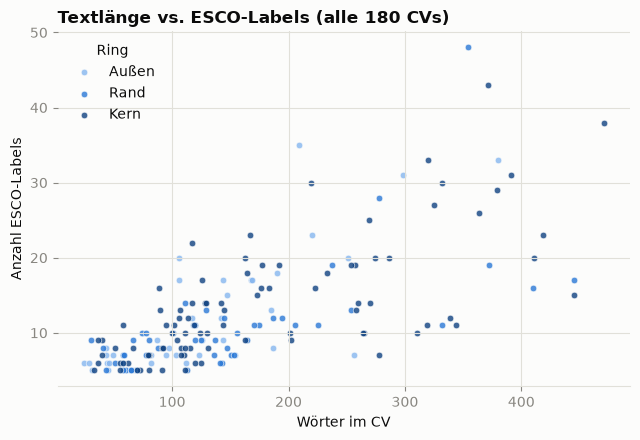

Korrelation Wörter ~ Labels: 0.73


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for ring in ["Außen", "Rand", "Kern"]:
    teil = cvs[cvs["ring_name"] == ring]
    ax.scatter(teil["n_words"], teil["n_labels"], s=22, color=FARBEN[ring], alpha=0.8,
               edgecolor=SURFACE, linewidth=0.5, label=ring)
ax.set_xlabel("Wörter im CV")
ax.set_ylabel("Anzahl ESCO-Labels")
ax.set_title("Textlänge vs. ESCO-Labels (alle 180 CVs)", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, title="Ring")
plt.tight_layout()
plt.show()

print(f"Korrelation Wörter ~ Labels: {cvs['n_words'].corr(cvs['n_labels'], method='spearman'):.2f}")

## 5. Englischniveau der CVs

Liste und Zwillinge zusammen, getrennt nach Ring. Wenn ein Ring deutlich besseres Englisch hat,
könnte das (über die Textlänge) die Scores mitprägen.

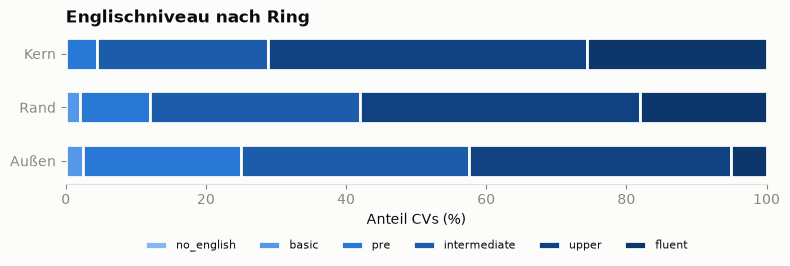

English Level,no_english,basic,pre,intermediate,upper,fluent
ring_name,,,,,,
Kern,0.0,0.0,4.0,24.0,46.0,26.0
Rand,0.0,2.0,10.0,30.0,40.0,18.0
Außen,0.0,2.0,22.0,32.0,38.0,5.0


In [9]:
level_order = ["no_english", "basic", "pre", "intermediate", "upper", "fluent"]
anteile = pd.crosstab(cvs["ring_name"], cvs["English Level"], normalize="index").reindex(
    index=["Kern", "Rand", "Außen"], columns=level_order, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(8, 3))
links = np.zeros(len(anteile))
for level, farbe in zip(level_order, BLUE_ORDINAL):
    ax.barh(anteile.index[::-1], anteile[level][::-1], left=links, color=farbe,
            edgecolor=SURFACE, linewidth=2, height=0.6, label=level)
    links += anteile[level][::-1].to_numpy()
ax.set_xlim(0, 100)
ax.set_xlabel("Anteil CVs (%)")
ax.set_title("Englischniveau nach Ring", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=8, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.3))
ax.grid(False)
plt.tight_layout()
plt.show()

anteile.round(0)

## 6. Erfahrung der CVs und der Jobs

Erfahrung fließt in MeritMe bewusst nicht ein. Wir schauen trotzdem hin, wie sie sich verteilt –
z. B. ob die Zwillinge eher Junioren sind, während die Jobs Senioren suchen.

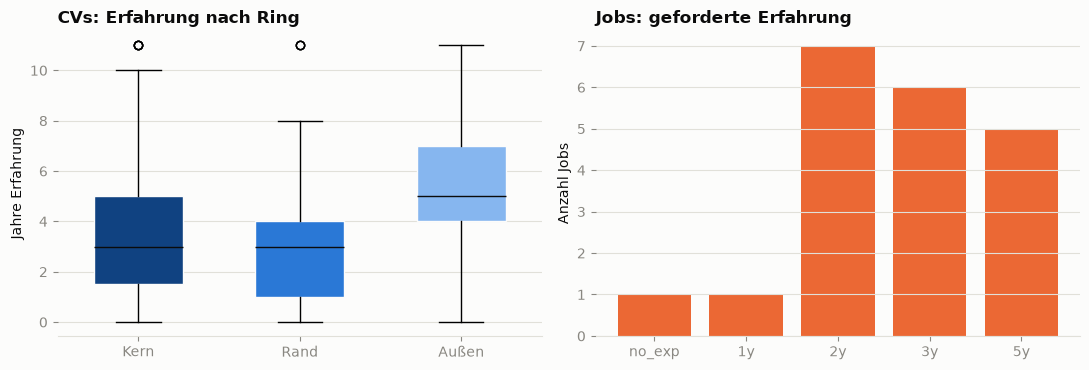

ring_name
Kern     3.0
Rand     3.0
Außen    5.0
Name: Experience Years, dtype: float64

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ringe = ["Kern", "Rand", "Außen"]
daten = [cvs.loc[cvs["ring_name"] == r, "Experience Years"] for r in ringe]
box = axes[0].boxplot(daten, patch_artist=True, widths=0.55, medianprops={"color": INK})
for patch, r in zip(box["boxes"], ringe):
    patch.set_facecolor(FARBEN[r])
    patch.set_edgecolor(SURFACE)
axes[0].set_xticks([1, 2, 3], ringe)
axes[0].set_ylabel("Jahre Erfahrung")
axes[0].set_title("CVs: Erfahrung nach Ring", loc="left", color=INK, fontweight="bold")
axes[0].grid(axis="x", visible=False)

exp_order = ["no_exp", "1y", "2y", "3y", "5y"]
job_exp = jobs["Exp Years"].value_counts().reindex(exp_order, fill_value=0)
axes[1].bar(job_exp.index, job_exp.values, color=ORANGE)
axes[1].set_ylabel("Anzahl Jobs")
axes[1].set_title("Jobs: geforderte Erfahrung", loc="left", color=INK, fontweight="bold")
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

cvs.groupby("ring_name")["Experience Years"].median().reindex(ringe)

## 7. Wer steckt dahinter? Titel und Stellen

Die 20 Jobs im Überblick und die häufigsten Positions-Titel der CVs je Ring.

In [11]:
jobs["Jahr"] = jobs["Published"].str[:4]
jobs[["Position", "Company Name", "Exp Years", "English Level", "Jahr", "n_labels"]].sort_values("Position")

,Position,Company Name,Exp Years,English Level,Jahr,n_labels
4,AWS Data Engineer,Arche Consulting,3y,upper,2023,15
8,Big Data,Nixwood,2y,upper,2021,5
12,Computer Vision Developer,Academy SMART,5y,upper,2022,10
18,Data Analyst Engineer (IRC111610),GlobalLogic,3y,intermediate,2021,20
9,Data Research Scientist ( fem tech),Mira,2y,fluent,2023,61
13,Data Science Consultant,Data Science UA,2y,fluent,2023,35
1,Data Science Specialist (with RASA experience),Axon,3y,intermediate,2022,26
5,Data Scientist,TheWhyKingz,2y,intermediate,2022,19
6,Data Scientist,Appflame,2y,NaN,2022,30
19,Data Scientist,IdeaSoft,3y,intermediate,2021,68


In [12]:
for ring in ["Kern", "Rand", "Außen"]:
    titel = cvs.loc[cvs["ring_name"] == ring, "Position"].str.strip().str.lower()
    print(f"--- {ring} ---")
    print(titel.value_counts().head(6).to_string())
    print()

--- Kern ---
Position
data scientist                   36
data analyst                      7
machine learning engineer         4
data scientist / data analyst     3
data scientist/data analyst       2
senior data scientist             2

--- Rand ---
Position
python developer            19
junior python developer      6
python/django developer      4
python software engineer     2
разработчик python           2
backend developer            2

--- Außen ---
Position
php developer               11
senior php developer         6
middle php developer         2
senior software engineer     2
wordpress developer          2
разработчик php              2



## 8. Wie sind die Zwillinge auf die Jobs verteilt?

Jeder der 20 Jobs bekommt 6 Zwillingspaare: 5 aus dem Haupttest (Kern + Rand) und 1 Kontrolle (Außen).

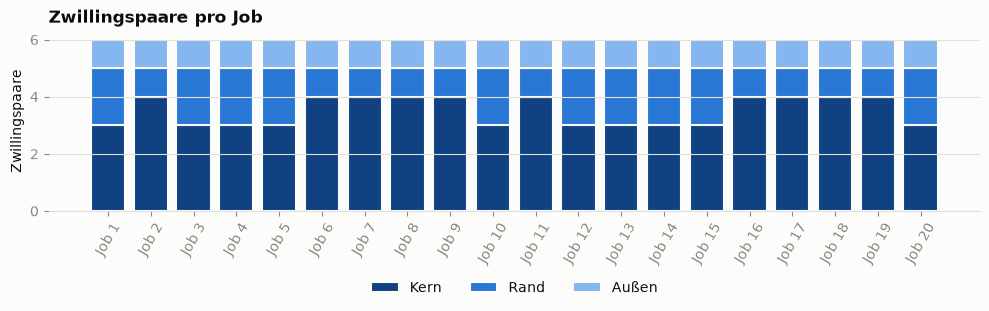

In [13]:
zwillinge = cvs[cvs["role"] == "twin_source"]
pro_job = pd.crosstab(zwillinge["assigned_job_id"], zwillinge["ring_name"]).reindex(columns=ringe)
pro_job.index = [f"Job {i + 1}" for i in range(len(pro_job))]

fig, ax = plt.subplots(figsize=(10, 3.5))
unten = np.zeros(len(pro_job))
for r in ringe:
    ax.bar(pro_job.index, pro_job[r], bottom=unten, color=FARBEN[r], edgecolor=SURFACE, linewidth=1.5, label=r)
    unten += pro_job[r].to_numpy()
ax.set_ylabel("Zwillingspaare")
ax.set_title("Zwillingspaare pro Job", loc="left", color=INK, fontweight="bold")
ax.tick_params(axis="x", rotation=60)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 9. Fazit

- **Größen stimmen:** 20 Jobs, Liste 20/20/20, Zwillinge 70/30/20. Jeder Job hat 6 Zwillingspaare.
- **Jobs sind etwa doppelt so lang wie CVs** (Median 245 gegenüber ~130 Wörtern) und haben entsprechend mehr ESCO-Labels (Median 24,5 gegenüber ~11). Die Ringe unterscheiden sich in der Länge kaum, nur Außen (PHP) ist etwas kürzer und hat weniger Labels (Median 8).
- **Mehr Text gibt mehr Labels** (Spearman 0,73), dasselbe Muster wie im Screening.
- **Die Ringe unterscheiden sich im Englischniveau:** *upper* oder *fluent* haben im Kern 72 %, im Rand 58 % und Außen 43 %. Ring und Englischniveau hängen also zusammen. Für den Zwillingstest ist das kein Problem, weil sich die beiden Zwillinge eines Paares nur im Stil unterscheiden. Unterschiede *zwischen* den Ringen sollte man aber nicht allein als Skill-Unterschied lesen.
- **Außen ist erfahrener:** PHP-CVs haben im Median 5 Jahre Erfahrung, Kern und Rand 3. Die Jobs fordern meist 2–5 Jahre.
- **Nicht alle „Data Science“-Jobs sind Data Science.** Unter den 20 Stellen sind ein *Rotating Equipment Specialist* (offensichtlich falsch verschlagwortet) und mehrere reine Data-Engineer-Stellen (*AWS Data Engineer*, *Middle/Senior Data Engineer*, *Big Data*). Das `Primary Keyword` ist also verrauscht. Bevor der Markt eingefroren wird, sollten wir die 20 Jobs von Hand durchsehen und unpassende nach einer festen Regel ersetzen (z. B. „Titel muss eine Data-Science-Rolle nennen“).
- **Die CV-Titel passen gut zu den Ringen** (*data scientist*, *python developer*, *php developer*). Einzelne Titel sind auf Russisch (*разработчик python*), obwohl der CV-Text englisch ist.